## Training & Testing CNNs on CIFAR10

In [1]:
%reload_ext autoreload
%autoreload 2

import MyCVLibrary as mylib

import numpy as np
import matplotlib.pyplot as plt
import torch
import torchvision
from torchvision.transforms import v2
import torch.nn as nn

In [2]:
testCNN = mylib.BasicCNN()
testCNN.print_layer_summary((3, 32, 32))

Conv2d output shape:	 torch.Size([1, 8, 32, 32])
ReLU output shape:	 torch.Size([1, 8, 32, 32])
MaxPool2d output shape:	 torch.Size([1, 8, 16, 16])
Conv2d output shape:	 torch.Size([1, 32, 16, 16])
ReLU output shape:	 torch.Size([1, 32, 16, 16])
MaxPool2d output shape:	 torch.Size([1, 32, 8, 8])
Conv2d output shape:	 torch.Size([1, 128, 8, 8])
ReLU output shape:	 torch.Size([1, 128, 8, 8])
MaxPool2d output shape:	 torch.Size([1, 128, 4, 4])
Flatten output shape:	 torch.Size([1, 2048])
Linear output shape:	 torch.Size([1, 120])
ReLU output shape:	 torch.Size([1, 120])
Linear output shape:	 torch.Size([1, 84])
ReLU output shape:	 torch.Size([1, 84])
Linear output shape:	 torch.Size([1, 10])


In [3]:
dataset = mylib.CIFAR10DataSet()
testCNN = mylib.BasicCNN()
testCNN.apply_param_init([next(iter(dataset.dataloader(train=True)))[0]], init_scheme=mylib.init_cnn_kaiming_normal)
trainer = mylib.CNNTrainer(model=testCNN, dataset=dataset, lr=1e-2, max_epochs=10)
trainer.train()
# 54s

Epoch: 1 Training loss: 1.62 Val Loss: 1.35 Val Accuracy: 52.13%
Epoch: 2 Training loss: 1.28 Val Loss: 1.18 Val Accuracy: 57.65%
Epoch: 3 Training loss: 1.10 Val Loss: 1.12 Val Accuracy: 60.21%
Epoch: 4 Training loss: 0.99 Val Loss: 1.07 Val Accuracy: 62.61%
Epoch: 5 Training loss: 0.89 Val Loss: 1.03 Val Accuracy: 64.38%
Epoch: 6 Training loss: 0.79 Val Loss: 1.04 Val Accuracy: 64.93%
Epoch: 7 Training loss: 0.71 Val Loss: 1.05 Val Accuracy: 64.63%
Epoch: 8 Training loss: 0.64 Val Loss: 1.03 Val Accuracy: 65.82%
Epoch: 9 Training loss: 0.57 Val Loss: 1.13 Val Accuracy: 65.20%
Epoch: 10 Training loss: 0.50 Val Loss: 1.08 Val Accuracy: 66.04%


In [ ]:
# Need to upsample CIFAR10 (32, 32) to (224, 224) to ensure downsampling of AlexNet dosen't
# reduce dimensions to 0
dataset = mylib.CIFAR10DataSet(resize=True, new_size=(224, 224))
MyAlexNetModel = mylib.MyAlexNet()
MyAlexNetModel.apply_param_init([next(iter(dataset.dataloader(train=True)))[0]], init_scheme=mylib.init_cnn_kaiming_normal)
trainer = mylib.CNNTrainer(model=MyAlexNetModel, dataset=dataset, lr=1e-2, max_epochs=10)
trainer.train()
# 3m35s

Epoch: 1 Training loss: 1.61 Val Loss: 1.28 Val Accuracy: 55.05%
Epoch: 2 Training loss: 1.14 Val Loss: 1.00 Val Accuracy: 66.06%
Epoch: 3 Training loss: 0.92 Val Loss: 0.82 Val Accuracy: 71.73%
Epoch: 4 Training loss: 0.76 Val Loss: 0.81 Val Accuracy: 72.53%
Epoch: 5 Training loss: 0.65 Val Loss: 0.74 Val Accuracy: 74.53%
Epoch: 6 Training loss: 0.56 Val Loss: 0.67 Val Accuracy: 77.35%
Epoch: 7 Training loss: 0.48 Val Loss: 0.66 Val Accuracy: 77.69%
Epoch: 8 Training loss: 0.40 Val Loss: 0.64 Val Accuracy: 79.17%
Epoch: 9 Training loss: 0.34 Val Loss: 0.63 Val Accuracy: 79.50%
Epoch: 10 Training loss: 0.28 Val Loss: 0.67 Val Accuracy: 79.96%


In [ ]:
dataset = mylib.CIFAR10DataSet(batch_size=128, resize=True, new_size=(224, 224))
MyVGGModel = mylib.MyVGGNet(model_arch=((16, 1, 3), (32, 1, 3), (64, 2, 3), (128, 2, 3), (128, 2, 3)))
MyVGGModel.apply_param_init([next(iter(dataset.dataloader(train=True)))[0]], init_scheme=mylib.init_cnn_kaiming_normal)
trainer = mylib.CNNTrainer(model=MyVGGModel, dataset=dataset, lr=1e-2, max_epochs=10)
trainer.train()
# 4m4s

Epoch: 1 Training loss: 1.82 Val Loss: 1.44 Val Accuracy: 47.89%
Epoch: 2 Training loss: 1.37 Val Loss: 1.28 Val Accuracy: 54.14%
Epoch: 3 Training loss: 1.15 Val Loss: 1.01 Val Accuracy: 64.24%
Epoch: 4 Training loss: 0.97 Val Loss: 0.86 Val Accuracy: 69.84%
Epoch: 5 Training loss: 0.85 Val Loss: 0.84 Val Accuracy: 70.82%
Epoch: 6 Training loss: 0.74 Val Loss: 0.73 Val Accuracy: 74.83%
Epoch: 7 Training loss: 0.66 Val Loss: 0.71 Val Accuracy: 75.62%
Epoch: 8 Training loss: 0.58 Val Loss: 0.68 Val Accuracy: 76.75%
Epoch: 9 Training loss: 0.51 Val Loss: 0.71 Val Accuracy: 76.90%
Epoch: 10 Training loss: 0.45 Val Loss: 0.67 Val Accuracy: 77.90%


In [ ]:
# Try again with VGG but wit different model_arch parameters
dataset = mylib.CIFAR10DataSet(batch_size=128, resize=True, new_size=(112, 112))
MyVGGModelV2 = mylib.MyVGGNet(model_arch=((16, 2, 5), (32, 2, 3), (128, 4, 3), (256, 4, 3)))
MyVGGModelV2.apply_param_init([next(iter(dataset.dataloader(train=True)))[0]], init_scheme=mylib.init_cnn_kaiming_normal)
trainer = mylib.CNNTrainer(model=MyVGGModelV2, dataset=dataset, lr=1e-2, max_epochs=10)
trainer.train()
# 4m8s

Epoch: 1 Training loss: 1.95 Val Loss: 1.57 Val Accuracy: 41.81%
Epoch: 2 Training loss: 1.52 Val Loss: 1.36 Val Accuracy: 49.65%
Epoch: 3 Training loss: 1.29 Val Loss: 1.11 Val Accuracy: 59.66%
Epoch: 4 Training loss: 1.10 Val Loss: 0.99 Val Accuracy: 64.08%
Epoch: 5 Training loss: 0.94 Val Loss: 0.88 Val Accuracy: 69.29%
Epoch: 6 Training loss: 0.82 Val Loss: 0.78 Val Accuracy: 72.18%
Epoch: 7 Training loss: 0.72 Val Loss: 0.71 Val Accuracy: 75.19%
Epoch: 8 Training loss: 0.63 Val Loss: 0.70 Val Accuracy: 76.20%
Epoch: 9 Training loss: 0.56 Val Loss: 0.68 Val Accuracy: 76.71%
Epoch: 10 Training loss: 0.49 Val Loss: 0.65 Val Accuracy: 78.81%


In [ ]:
# Same thing as above, but with 15 epochs (instead of 10) out of curiousity
dataset = mylib.CIFAR10DataSet(batch_size=128, resize=True, new_size=(112, 112))
MyVGGModelV2 = mylib.MyVGGNet(model_arch=((16, 2, 5), (32, 2, 3), (128, 4, 3), (256, 4, 3)))
MyVGGModelV2.apply_param_init([next(iter(dataset.dataloader(train=True)))[0]], init_scheme=mylib.init_cnn_kaiming_normal)
trainer = mylib.CNNTrainer(model=MyVGGModelV2, dataset=dataset, lr=1e-2, max_epochs=15)
trainer.train()
# 5m53s

Epoch: 1 Training loss: 1.81 Val Loss: 1.45 Val Accuracy: 46.68%
Epoch: 2 Training loss: 1.37 Val Loss: 1.22 Val Accuracy: 55.49%
Epoch: 3 Training loss: 1.13 Val Loss: 1.03 Val Accuracy: 63.83%
Epoch: 4 Training loss: 0.97 Val Loss: 0.91 Val Accuracy: 68.33%
Epoch: 5 Training loss: 0.85 Val Loss: 0.85 Val Accuracy: 70.20%
Epoch: 6 Training loss: 0.76 Val Loss: 0.77 Val Accuracy: 73.12%
Epoch: 7 Training loss: 0.67 Val Loss: 0.74 Val Accuracy: 75.00%
Epoch: 8 Training loss: 0.60 Val Loss: 0.68 Val Accuracy: 76.75%
Epoch: 9 Training loss: 0.53 Val Loss: 0.67 Val Accuracy: 77.72%
Epoch: 10 Training loss: 0.46 Val Loss: 0.62 Val Accuracy: 79.14%
Epoch: 11 Training loss: 0.41 Val Loss: 0.69 Val Accuracy: 77.91%
Epoch: 12 Training loss: 0.36 Val Loss: 0.66 Val Accuracy: 79.23%
Epoch: 13 Training loss: 0.31 Val Loss: 0.63 Val Accuracy: 79.68%
Epoch: 14 Training loss: 0.27 Val Loss: 0.74 Val Accuracy: 78.98%
Epoch: 15 Training loss: 0.22 Val Loss: 0.71 Val Accuracy: 80.09%


In [ ]:
dataset = mylib.CIFAR10DataSet(batch_size=64, resize=True, new_size=(224, 224))
MyGoogLeNetModel = mylib.MyGoogLeNet()
MyGoogLeNetModel.apply_param_init([next(iter(dataset.dataloader(train=True)))[0]], init_scheme=mylib.init_cnn_kaiming_normal)
# Initialized. Check summary then train
    # MyGoogLeNetModel.print_layer_summary((3, 224, 224))
trainer = mylib.CNNTrainer(model=MyGoogLeNetModel, dataset=dataset, lr=1e-2, max_epochs=10)
trainer.train()
# 7m19s

Epoch: 1 Training loss: 1.77 Val Loss: 1.66 Val Accuracy: 37.48%
Epoch: 2 Training loss: 1.38 Val Loss: 1.26 Val Accuracy: 54.22%
Epoch: 3 Training loss: 1.16 Val Loss: 1.08 Val Accuracy: 61.89%
Epoch: 4 Training loss: 0.98 Val Loss: 0.99 Val Accuracy: 64.16%
Epoch: 5 Training loss: 0.84 Val Loss: 0.85 Val Accuracy: 70.10%
Epoch: 6 Training loss: 0.73 Val Loss: 1.01 Val Accuracy: 66.23%
Epoch: 7 Training loss: 0.65 Val Loss: 0.64 Val Accuracy: 78.27%
Epoch: 8 Training loss: 0.58 Val Loss: 0.63 Val Accuracy: 78.89%
Epoch: 9 Training loss: 0.52 Val Loss: 0.57 Val Accuracy: 80.72%
Epoch: 10 Training loss: 0.47 Val Loss: 0.59 Val Accuracy: 80.89%


In [ ]:
# Same GoogLeNet as cell above but for 15 epochs. Val loss dropping asw indicates not overfitting yet
# Try 15 epochs cuz y not
dataset = mylib.CIFAR10DataSet(batch_size=64, resize=True, new_size=(224, 224))
MyGoogLeNetModel = mylib.MyGoogLeNet()
MyGoogLeNetModel.apply_param_init([next(iter(dataset.dataloader(train=True)))[0]], init_scheme=mylib.init_cnn_kaiming_normal)
trainer = mylib.CNNTrainer(model=MyGoogLeNetModel, dataset=dataset, lr=1e-2, max_epochs=15)
trainer.train()
# 10m31s

Epoch: 1 Training loss: 1.77 Val Loss: 1.45 Val Accuracy: 43.91%
Epoch: 2 Training loss: 1.37 Val Loss: 1.28 Val Accuracy: 51.45%
Epoch: 3 Training loss: 1.15 Val Loss: 1.25 Val Accuracy: 54.47%
Epoch: 4 Training loss: 0.97 Val Loss: 0.94 Val Accuracy: 67.43%
Epoch: 5 Training loss: 0.84 Val Loss: 0.85 Val Accuracy: 70.34%
Epoch: 6 Training loss: 0.73 Val Loss: 0.82 Val Accuracy: 71.94%
Epoch: 7 Training loss: 0.65 Val Loss: 0.68 Val Accuracy: 76.76%
Epoch: 8 Training loss: 0.57 Val Loss: 0.61 Val Accuracy: 79.30%
Epoch: 9 Training loss: 0.52 Val Loss: 0.58 Val Accuracy: 80.24%
Epoch: 10 Training loss: 0.46 Val Loss: 0.71 Val Accuracy: 76.70%
Epoch: 11 Training loss: 0.43 Val Loss: 0.54 Val Accuracy: 81.93%
Epoch: 12 Training loss: 0.38 Val Loss: 0.64 Val Accuracy: 78.56%
Epoch: 13 Training loss: 0.35 Val Loss: 0.61 Val Accuracy: 79.62%
Epoch: 14 Training loss: 0.31 Val Loss: 0.55 Val Accuracy: 82.18%
Epoch: 15 Training loss: 0.29 Val Loss: 0.53 Val Accuracy: 83.34%


In [ ]:
# ResNet-18 
MyResNet18 = mylib.MyShallowResNet(model_arch=((2, 64), (2, 128), (2, 256), (2, 512),))
MyResNet18.print_layer_summary((3, 224, 224))
dataset = mylib.CIFAR10DataSet(batch_size=64, resize=True, new_size=(224, 224))
# MyResNet18.apply_param_init([next(iter(dataset.dataloader(train=True)))[0]], init_scheme=mylib.init_cnn_kaiming_normal)
trainer = mylib.CNNTrainer(model=MyResNet18, dataset=dataset, lr=1e-2, max_epochs=10)
trainer.train()
# 6m22s

Sequential output shape:	 torch.Size([1, 64, 56, 56])
Sequential output shape:	 torch.Size([1, 512, 7, 7])
Sequential output shape:	 torch.Size([1, 10])
Epoch: 1 Training loss: 1.26 Val Loss: 0.96 Val Accuracy: 66.82%
Epoch: 2 Training loss: 0.72 Val Loss: 0.88 Val Accuracy: 70.79%
Epoch: 3 Training loss: 0.51 Val Loss: 0.68 Val Accuracy: 77.01%
Epoch: 4 Training loss: 0.38 Val Loss: 0.56 Val Accuracy: 80.78%
Epoch: 5 Training loss: 0.26 Val Loss: 0.67 Val Accuracy: 78.83%
Epoch: 6 Training loss: 0.18 Val Loss: 0.55 Val Accuracy: 82.54%
Epoch: 7 Training loss: 0.11 Val Loss: 0.61 Val Accuracy: 82.88%
Epoch: 8 Training loss: 0.07 Val Loss: 0.70 Val Accuracy: 82.01%
Epoch: 9 Training loss: 0.06 Val Loss: 0.84 Val Accuracy: 79.72%
Epoch: 10 Training loss: 0.04 Val Loss: 0.76 Val Accuracy: 81.84%


In [ ]:
# ResNet-18 for 4 epochs only
MyResNet18 = mylib.MyShallowResNet(model_arch=((2, 64), (2, 128), (2, 256), (2, 512),))
MyResNet18.print_layer_summary((3, 224, 224))
dataset = mylib.CIFAR10DataSet(batch_size=64, resize=True, new_size=(224, 224))
# MyResNet18.apply_param_init([next(iter(dataset.dataloader(train=True)))[0]], init_scheme=mylib.init_cnn_kaiming_normal)
trainer = mylib.CNNTrainer(model=MyResNet18, dataset=dataset, lr=1e-2, max_epochs=4)
trainer.train()
# 2m44s

Sequential output shape:	 torch.Size([1, 64, 56, 56])
Sequential output shape:	 torch.Size([1, 512, 7, 7])
Sequential output shape:	 torch.Size([1, 10])
Epoch: 1 Training loss: 1.28 Val Loss: 1.04 Val Accuracy: 62.99%
Epoch: 2 Training loss: 0.72 Val Loss: 0.77 Val Accuracy: 73.87%
Epoch: 3 Training loss: 0.51 Val Loss: 0.62 Val Accuracy: 79.10%
Epoch: 4 Training loss: 0.37 Val Loss: 0.66 Val Accuracy: 77.73%


In [3]:
MyResNet50 = mylib.MyDeepResNet(model_arch=((3, 64, 256), (4, 128, 512), (6, 256, 1024), (3, 512, 2048)))
MyResNet50.print_layer_summary((3, 224, 224))

Sequential output shape:	 torch.Size([1, 64, 56, 56])
Sequential output shape:	 torch.Size([1, 2048, 7, 7])
Sequential output shape:	 torch.Size([1, 10])


In [ ]:
# Test train MyResNet50
MyResNet50 = mylib.MyDeepResNet(model_arch=((3, 64, 256), (4, 128, 512), (6, 256, 1024), (3, 512, 2048)))
dataset = mylib.CIFAR10DataSet(batch_size=64, resize=True, new_size=(224, 224))
MyResNet50.apply_param_init([next(iter(dataset.dataloader(train=True)))[0]], init_scheme=mylib.init_cnn_kaiming_normal)
trainer = mylib.CNNTrainer(model=MyResNet50, dataset=dataset, max_epochs=10)
trainer.train()
# 19m26s

Epoch: 1 Training loss: 1.91 Val Loss: 1.49 Val Accuracy: 45.78%
Epoch: 2 Training loss: 1.32 Val Loss: 1.34 Val Accuracy: 56.28%
Epoch: 3 Training loss: 1.04 Val Loss: 0.94 Val Accuracy: 66.66%
Epoch: 4 Training loss: 0.84 Val Loss: 1.00 Val Accuracy: 68.06%
Epoch: 5 Training loss: 0.69 Val Loss: 0.79 Val Accuracy: 72.83%
Epoch: 6 Training loss: 0.55 Val Loss: 0.89 Val Accuracy: 75.29%
Epoch: 7 Training loss: 0.44 Val Loss: 0.85 Val Accuracy: 72.69%
Epoch: 8 Training loss: 0.35 Val Loss: 0.77 Val Accuracy: 77.08%
Epoch: 9 Training loss: 0.26 Val Loss: 1.03 Val Accuracy: 75.89%
Epoch: 10 Training loss: 0.21 Val Loss: 0.96 Val Accuracy: 75.78%


## Training Augments

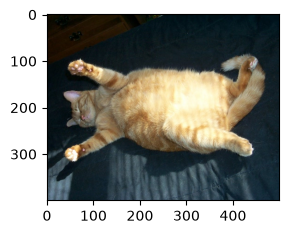

In [8]:
plt.figure(figsize=(3, 4))
cat_image = plt.imread('../img/cat1.jpg')
plt.imshow(cat_image)

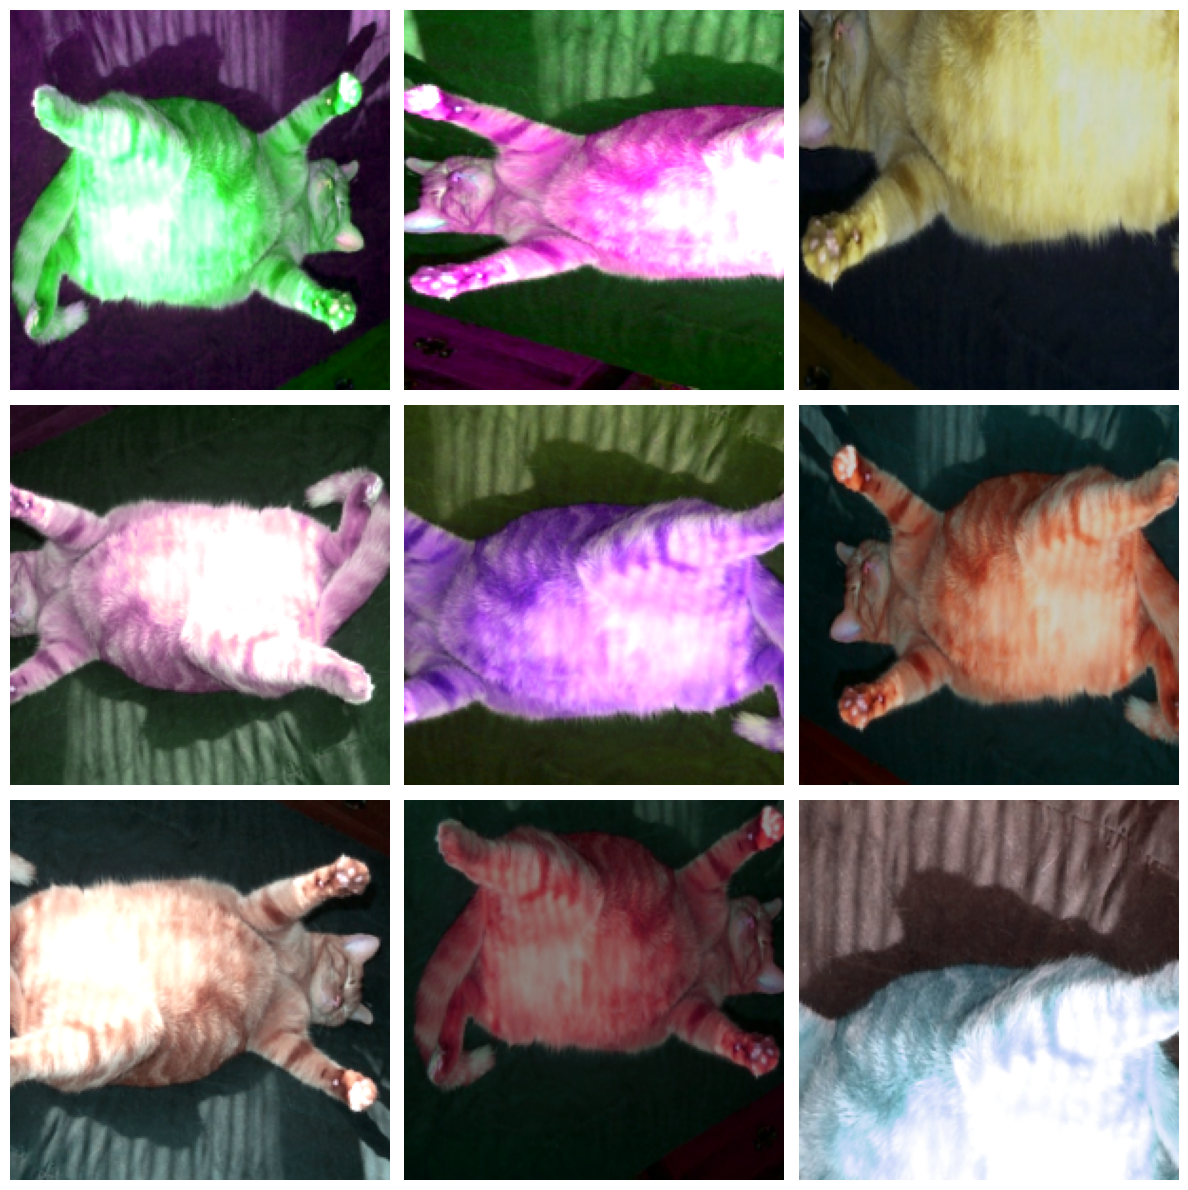

In [31]:
transforms = v2.Compose([v2.RandomHorizontalFlip(), 
                         v2.RandomVerticalFlip(), 
                         v2.RandomResizedCrop(size=(200, 200), scale=(0.2, 1.0), ratio=(0.5, 2.0)),
                         v2.ColorJitter(brightness=0.5, contrast=0, saturation=0.5, hue=0.5)])
mylib.apply_transforms(cat_image, transforms, num_rows=3, num_cols=3)

v2.ColorJitter() settings 

brightness=0.5


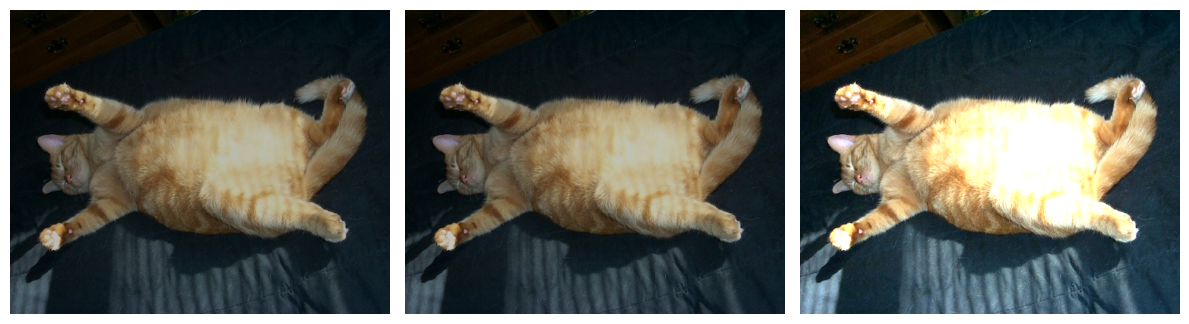

contrast=0.5


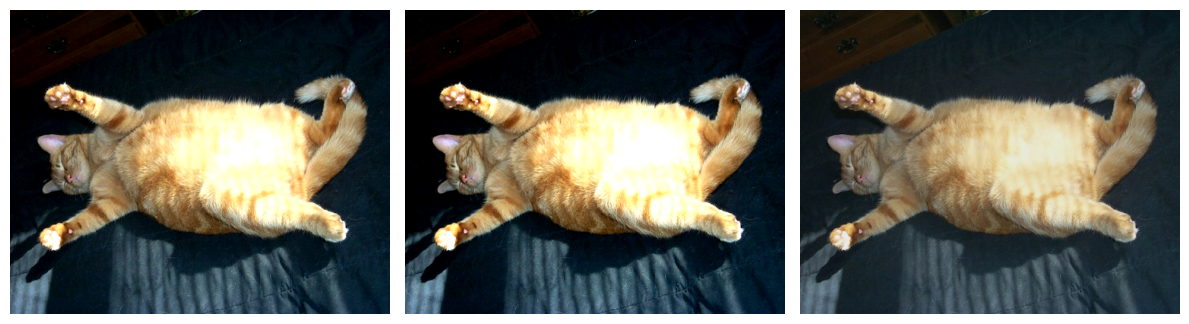

saturation=0.5


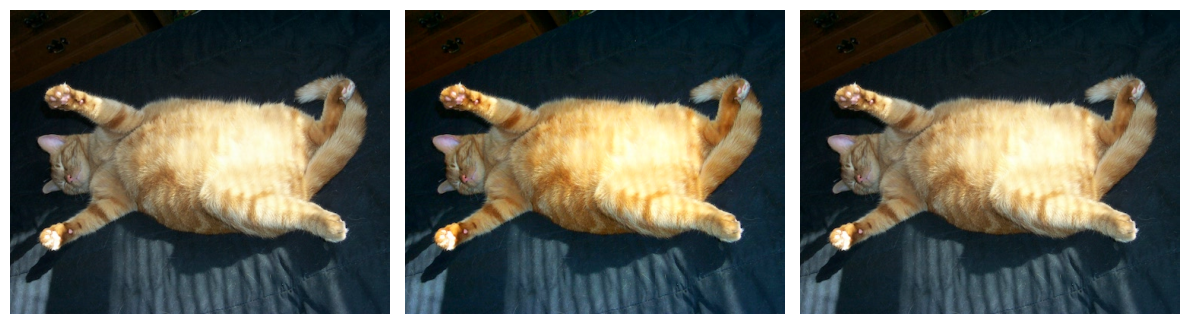

hue=0.5


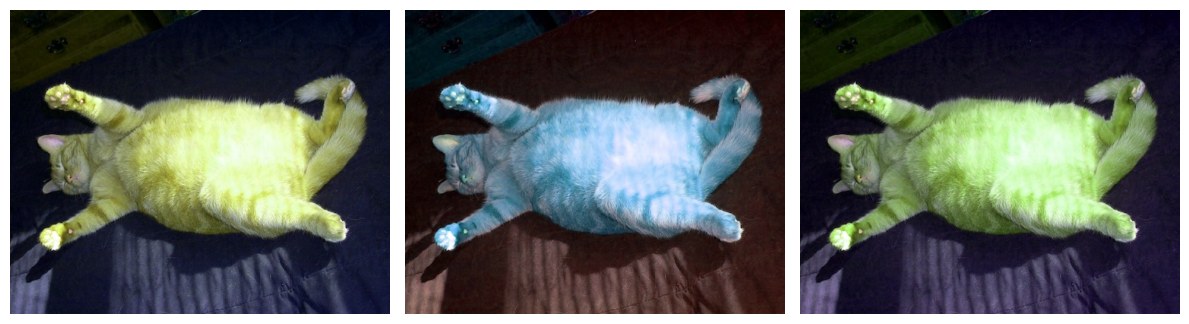

In [34]:
print("v2.ColorJitter() settings \n")

print("brightness=0.5")
transforms = v2.ColorJitter(brightness=0.5)
mylib.apply_transforms(cat_image, transforms, num_rows=1, num_cols=3)

print("contrast=0.5")
transforms = v2.ColorJitter(contrast=0.5)
mylib.apply_transforms(cat_image, transforms, num_rows=1, num_cols=3)

print("saturation=0.5")
transforms = v2.ColorJitter(saturation=0.5)
mylib.apply_transforms(cat_image, transforms, num_rows=1, num_cols=3)

print("hue=0.5")
transforms = v2.ColorJitter(hue=0.5)
mylib.apply_transforms(cat_image, transforms, num_rows=1, num_cols=3)



In [ ]:
MyResNet18 = mylib.MyShallowResNet(model_arch=((2, 64), (2, 128), (2, 256), (2, 512),))

In [ ]:
# Default AlexNet training (again)

# Need to upsample CIFAR10 (32, 32) to (224, 224) to ensure downsampling of AlexNet dosen't
# reduce dimensions to 0
dataset = mylib.CIFAR10DataSet(resize=True, batch_size=128, new_size=(224, 224))
MyAlexNetModel = mylib.MyAlexNet()
MyAlexNetModel.apply_param_init([next(iter(dataset.dataloader(train=True)))[0]], init_scheme=mylib.init_cnn_kaiming_normal)
trainer = mylib.CNNTrainer(model=MyAlexNetModel, dataset=dataset, lr=1e-2, max_epochs=10)
trainer.train()
# 3m35s (copied from before)
# 4m49s this time

Epoch: 1 Training loss: 1.69 Val Loss: 1.31 Val Accuracy: 53.69%
Epoch: 2 Training loss: 1.16 Val Loss: 1.06 Val Accuracy: 63.17%
Epoch: 3 Training loss: 0.93 Val Loss: 0.90 Val Accuracy: 68.78%
Epoch: 4 Training loss: 0.79 Val Loss: 0.78 Val Accuracy: 73.04%
Epoch: 5 Training loss: 0.67 Val Loss: 0.68 Val Accuracy: 76.26%
Epoch: 6 Training loss: 0.58 Val Loss: 0.64 Val Accuracy: 78.38%
Epoch: 7 Training loss: 0.50 Val Loss: 0.65 Val Accuracy: 78.05%
Epoch: 8 Training loss: 0.42 Val Loss: 0.62 Val Accuracy: 79.26%
Epoch: 9 Training loss: 0.36 Val Loss: 0.69 Val Accuracy: 77.87%
Epoch: 10 Training loss: 0.30 Val Loss: 0.70 Val Accuracy: 79.12%


In [37]:
# AlexNet training with Training Augments
training_augments = [v2.ColorJitter(brightness=0.5, contrast=0.5, hue=0.5), 
                     v2.RandomHorizontalFlip()]
                     # v2.RandomResizedCrop(size=(224, 224), scale=(0.2, 1.0), ratio=(0.5, 2.0))]

# Need to upsample CIFAR10 (32, 32) to (224, 224) to ensure downsampling of AlexNet dosen't
# reduce dimensions to 0
dataset = mylib.CIFAR10DataSet(batch_size=128, resize=True, new_size=(224, 224), train_augments=training_augments)
MyAlexNetModel = mylib.MyAlexNet()
MyAlexNetModel.apply_param_init([next(iter(dataset.dataloader(train=True)))[0]], init_scheme=mylib.init_cnn_kaiming_normal)
trainer = mylib.CNNTrainer(model=MyAlexNetModel, dataset=dataset, lr=1e-2, max_epochs=20)
trainer.train()
# 

Epoch: 1 Training loss: 2.30 Val Loss: 2.21 Val Accuracy: 15.72%
Epoch: 2 Training loss: 2.09 Val Loss: 1.75 Val Accuracy: 36.38%
Epoch: 3 Training loss: 1.61 Val Loss: 1.38 Val Accuracy: 52.19%
Epoch: 4 Training loss: 1.29 Val Loss: 1.09 Val Accuracy: 62.32%
Epoch: 5 Training loss: 1.08 Val Loss: 0.92 Val Accuracy: 67.91%
Epoch: 6 Training loss: 0.95 Val Loss: 0.83 Val Accuracy: 71.51%
Epoch: 7 Training loss: 0.87 Val Loss: 0.82 Val Accuracy: 72.13%
Epoch: 8 Training loss: 0.79 Val Loss: 0.80 Val Accuracy: 72.35%
Epoch: 9 Training loss: 0.73 Val Loss: 0.73 Val Accuracy: 75.25%
Epoch: 10 Training loss: 0.68 Val Loss: 0.69 Val Accuracy: 76.19%
Epoch: 11 Training loss: 0.64 Val Loss: 0.68 Val Accuracy: 76.78%
Epoch: 12 Training loss: 0.60 Val Loss: 0.65 Val Accuracy: 78.07%
Epoch: 13 Training loss: 0.56 Val Loss: 0.61 Val Accuracy: 79.59%
Epoch: 14 Training loss: 0.52 Val Loss: 0.64 Val Accuracy: 78.47%
Epoch: 15 Training loss: 0.50 Val Loss: 0.62 Val Accuracy: 79.46%
Epoch: 16 Training 

## Fine Tuning

In [46]:
# Fine tune pre-trained ResNet-18 on CIFAR10
# https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.resnet18.html
pretrained_ResNet18 = torchvision.models.resnet18(weights=torchvision.models.ResNet18_Weights.DEFAULT, progress=True)

for name, module in pretrained_ResNet18.named_children():
    print(name, module)

conv1 Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
bn1 BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
relu ReLU(inplace=True)
maxpool MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
layer1 Sequential(
  (0): BasicBlock(
    (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  )
  (1): BasicBlock(
    (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (conv2): 

In [47]:
for name, module in pretrained_ResNet18.named_modules():
    print(name, module.__class__.__name__)

 ResNet
conv1 Conv2d
bn1 BatchNorm2d
relu ReLU
maxpool MaxPool2d
layer1 Sequential
layer1.0 BasicBlock
layer1.0.conv1 Conv2d
layer1.0.bn1 BatchNorm2d
layer1.0.relu ReLU
layer1.0.conv2 Conv2d
layer1.0.bn2 BatchNorm2d
layer1.1 BasicBlock
layer1.1.conv1 Conv2d
layer1.1.bn1 BatchNorm2d
layer1.1.relu ReLU
layer1.1.conv2 Conv2d
layer1.1.bn2 BatchNorm2d
layer2 Sequential
layer2.0 BasicBlock
layer2.0.conv1 Conv2d
layer2.0.bn1 BatchNorm2d
layer2.0.relu ReLU
layer2.0.conv2 Conv2d
layer2.0.bn2 BatchNorm2d
layer2.0.downsample Sequential
layer2.0.downsample.0 Conv2d
layer2.0.downsample.1 BatchNorm2d
layer2.1 BasicBlock
layer2.1.conv1 Conv2d
layer2.1.bn1 BatchNorm2d
layer2.1.relu ReLU
layer2.1.conv2 Conv2d
layer2.1.bn2 BatchNorm2d
layer3 Sequential
layer3.0 BasicBlock
layer3.0.conv1 Conv2d
layer3.0.bn1 BatchNorm2d
layer3.0.relu ReLU
layer3.0.conv2 Conv2d
layer3.0.bn2 BatchNorm2d
layer3.0.downsample Sequential
layer3.0.downsample.0 Conv2d
layer3.0.downsample.1 BatchNorm2d
layer3.1 BasicBlock
layer3.1

In [6]:
pretrained_ResNet18.parameters

<bound method Module.parameters of ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine

In [ ]:
object = mylib.CIFAR10DataSet()
# len(object.training_set.classes)

pretrained_ResNet18.fc = nn.Linear(in_features=pretrained_ResNet18.fc.in_features, out_features=len(object.training_set.classes))
nn.init.kaiming_normal_(pretrained_ResNet18.fc.weight)



In [ ]:
# Fine tune pretrained ResNet-18 on CIFAR10. Train only last nn.Linear, with pretrained weights frozen
dataset = mylib.CIFAR10DataSet(resize=True, new_size=(224, 224))

pretrained_ResNet18 = torchvision.models.resnet18(weights=torchvision.models.ResNet18_Weights.DEFAULT)
pretrained_ResNet18.fc = nn.Linear(in_features=pretrained_ResNet18.fc.in_features, 
                                   out_features=len(dataset.training_set.classes))
nn.init.kaiming_normal_(pretrained_ResNet18.fc.weight)

trainer = mylib.FineTuneTrainer(model=pretrained_ResNet18, dataset=dataset, lr=1e-2, max_epochs=5)
trainer.train()

Epoch: 1 Training loss: 0.79 Val Loss: 0.64 Val Accuracy: 78.09%
Epoch: 2 Training loss: 0.60 Val Loss: 0.59 Val Accuracy: 79.80%
Epoch: 3 Training loss: 0.58 Val Loss: 0.63 Val Accuracy: 78.63%
Epoch: 4 Training loss: 0.57 Val Loss: 0.59 Val Accuracy: 80.28%
Epoch: 5 Training loss: 0.56 Val Loss: 0.60 Val Accuracy: 79.60%


In [ ]:
# Train pretrained weights at 1/10 lr of new last linear layer
dataset = mylib.CIFAR10DataSet(resize=True, new_size=(224, 224))
pretrained_ResNet18 = torchvision.models.resnet18(weights=torchvision.models.ResNet18_Weights.DEFAULT)
pretrained_ResNet18.fc = nn.Linear(in_features=pretrained_ResNet18.fc.in_features, 
                                   out_features=len(dataset.training_set.classes))
nn.init.kaiming_normal_(pretrained_ResNet18.fc.weight)

trainer = mylib.FineTuneTrainer(model=pretrained_ResNet18, dataset=dataset, lr=1e-2, max_epochs=5, 
                                 freeze_pretrained=False, pretrained_lr_multiplier=0.1)
trainer.train()

Epoch: 1 Training loss: 0.45 Val Loss: 0.24 Val Accuracy: 91.62%
Epoch: 2 Training loss: 0.16 Val Loss: 0.21 Val Accuracy: 92.82%
Epoch: 3 Training loss: 0.09 Val Loss: 0.19 Val Accuracy: 93.57%
Epoch: 4 Training loss: 0.05 Val Loss: 0.19 Val Accuracy: 94.04%
Epoch: 5 Training loss: 0.03 Val Loss: 0.19 Val Accuracy: 94.07%


## Vision Transformer Implementation
* Everything copied over to MyCNNLibrary now. Just

In [5]:
class ImagePatchEmbed(nn.Module):
    def __init__(self, image_size=64, patch_size=16, dim_embed=512):
        """
        Implementation Notes:
        - Convolution layer with number of output channels as dim_embed where both
        the kernel_size and stride are set to patch_size to create non-overlapping
        "snapshots" with the kernel 
        """
        super().__init__()
        def return_tuple(x):
            if not isinstance(x, (list, tuple)):
                return (x, x)
            return x
        image_size = return_tuple(image_size)
        patch_size = return_tuple(patch_size)
        self.num_patches = ((image_size[0] // patch_size[0]) * 
                            (image_size[1] // patch_size[1]))
        self.ConvProjection = nn.Conv2d(in_channels=3, out_channels=dim_embed, 
                                        kernel_size=patch_size, stride=patch_size)
        
    def forward(self, X):
        """
        Implementation Notes:
        - ConvLayer will return: (B, C, H, W). Want to flatten spatial dims.
        - Then, swap the channels and flattened spatial dims. We want projected
        embedding vector last, and H_out, W_out of the ConvLayer will correspond
        to number of vertical and horizontal patches, flattening will combine all 
        patches to a single dimension. 
        """
        projection_output = self.ConvProjection(X) # Line Output: (B, C_out, H_out, W_out)
        combined_patches = projection_output.flatten(start_dim=2, end_dim=3) # Line Output: (B, C_out, num_patches)
        transposed = combined_patches.transpose(1, 2) # Line Output: (B, num_patches, C_out)
        return transposed

In [6]:
image_size = 64
patch_size = 16
batch_size = 16
dim_embed  = 512

patch_embedding = ImagePatchEmbed(image_size=image_size, patch_size=patch_size, dim_embed=dim_embed)
test_train_batch = torch.zeros(batch_size, 3, image_size, image_size)

test_output = patch_embedding(test_train_batch)
print("test output shape: \t", test_output.shape)
print("expected output shape: \t", (batch_size, (image_size // patch_size)**2, dim_embed))


test output shape: 	 torch.Size([16, 16, 512])
expected output shape: 	 (16, 16, 512)


In [7]:
class VisionTransformerMLP(nn.Module):
    def __init__(self, num_hiddens, num_outputs, dropout=0.5):
        """
        Implementation Notes:
        - MLP block has 2 layers with a single GELU non-linearity. 
        - LayerNorm normalization applied before the MLP block (and
        also before the Multi-Head Self-Attention block, thus not 
        included here)
        """
        super().__init__()
        self.net = nn.Sequential(nn.LazyLinear(out_features=num_hiddens), 
                                 nn.GELU(), nn.Dropout(p=dropout), 
                                 nn.LazyLinear(out_features=num_outputs),
                                 nn.Dropout(p=dropout))
        
    def forward(self, X):
        return self.net(X)
    

class VisionTransformerBlock(nn.Module):
    def __init__(self, dim_embed, mlp_num_hidden, 
                 num_attn_heads, dropout_prob, use_bias=False):
        super().__init__()
        assert dim_embed % num_attn_heads == 0

        self.LayerNorm1 = nn.LayerNorm(normalized_shape=dim_embed)
        self.MHSAttention = nn.MultiheadAttention(embed_dim=dim_embed, num_heads=num_attn_heads, 
                                                  dropout=dropout_prob, bias=use_bias, batch_first=True)
        
        self.LayerNorm2 = nn.LayerNorm(normalized_shape=dim_embed)
        self.MLP = VisionTransformerMLP(num_hiddens=mlp_num_hidden, num_outputs=dim_embed, dropout=dropout_prob)

    def forward(self, X):
        """
        Implementation Notes
        - Discard _ output of MHSA. Don't need weights themselves, onlt the transformation
        - Reference Fig. 1 of ViT 16x16 Image
        - Pre-LayerNorm (1) before Multi-Head Self-Attention (MHSA)
        - Residual connection from before LayerNorm (1) to output of MHSA
        - Pre-LayerNorm (2) before MLP Block
        - Residual connection from before LayerNorm (2) to output of MLP
        - Output of current transformer encoder block
        """
        Y = self.LayerNorm1(X)
        attn_output_transformation, _ = self.MHSAttention(query=Y, key=Y, value=Y, need_weights=False)
        X = X + attn_output_transformation

        A = self.LayerNorm2(X)
        B = self.MLP(A)
        block_output = X + B
        return block_output

In [8]:
# Test ViT block I/O dimensions
test_input = torch.ones((2, 16, 256))
encoder_block = VisionTransformerBlock(dim_embed=256, mlp_num_hidden=64, num_attn_heads=8, dropout_prob=0.5)
encoder_block.eval()

print("shape of encoder block output: \t", encoder_block(test_input).shape)
print("shape of encoder block input: \t", test_input.shape)

shape of encoder block output: 	 torch.Size([2, 16, 256])
shape of encoder block input: 	 torch.Size([2, 16, 256])


In [ ]:
# Final classification head indexing & extraction
input_tensor = torch.randn(size=(64, 37, 512))
print("output_tensor shape is:\t", input_tensor.shape)

# Selected out
# Select out the 0th token for all batches, and the entire embedding of said 0th token. 
# Thus, should result in output shape of: (batch_size, dim_embed)
output   = input_tensor[:, 0, :] 
outputV2 = input_tensor[:, 0]
print("classification head:\t", output.shape)
print(output == outputV2)

output_tensor shape is:	 torch.Size([64, 37, 512])
classification head:	 torch.Size([64, 512])
tensor([[True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        ...,
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True]])


In [ ]:
class VisionTransformer(nn.Module):
    def __init__(self, image_size, patch_size, dim_embed, mlp_num_hiddens, num_attn_heads, num_ViT_blocks, 
                emb_dropout_prob, mlp_dropout_prob, lr=0.01, use_bias=False, num_classes=10):
        """
        Implementation Notes:
        - Use learned positional embeddings for now, since paper says they didn't notice any
        difference between fixed/learned. 
        - NOTE - come back later and add versions/options for 
        trigonometric embedding and rotational positional embedding
        """
        super().__init__()
        self.patch_embeddings = ImagePatchEmbed(image_size=image_size, patch_size=patch_size, 
                                                dim_embed=dim_embed)
        self.class_token = nn.Parameter(torch.zeros(1, 1, dim_embed))
        num_tokens = self.patch_embeddings.num_patches + 1 
        self.position_embedding = nn.Parameter(torch.randn(1, num_tokens, dim_embed))
        self.dropout = nn.Dropout(p=emb_dropout_prob)
        
        self.StackedTransformerEncoders = nn.Sequential()
        for jj in range(num_ViT_blocks):
            self.StackedTransformerEncoders.add_module(f"{jj}", VisionTransformerBlock(
                dim_embed=dim_embed, mlp_num_hidden=mlp_num_hiddens, num_attn_heads=num_attn_heads,
                dropout_prob=mlp_dropout_prob, use_bias=use_bias
            ))
        self.classification_head = nn.Sequential(nn.LayerNorm(normalized_shape=dim_embed), 
                                                 nn.Linear(in_features=dim_embed, out_features=num_classes))

    def forward(self, X):
        # Pass raw image through patch embeddings
        X = self.patch_embeddings(X)

        # Concatenate class token at first position
        # Expand the class_token from: (1, 1, dim_embed) to: (batch_size, 1, dim_embed). The -1 mean to keep unchanged
        # Concatenate by putting class token in front of patch embedding tokens and concatenating along token dimension
        # Note: .expand() is used to create a new view of it by treating same parameter(s) as appearing 
        # multiple times across batches without copying its data. Backprop will accumulate all gradients across
        # batch samples back into single class token vector
        X = torch.cat((self.class_token.expand(X.shape[0], -1, -1), X), dim=1)

        # Add positional embedding to embedding vectors
        X = self.dropout(X + self.position_embedding)

        # Pass embeddings through all transformer encoder blocks
        for block in self.StackedTransformerEncoders:
            X = block(X)

        output = self.classification_head(X[:, 0, :]) # Line Input: (batch_size, dim_embed). Line Output: (batch_size, num_classes)
        return output

In [ ]:
# ViT Hyperparameter Set #1
image_size = 96
patch_size = 16
dim_embed = 768
mlp_num_hiddens = 1024
num_attn_heads = 16
num_transformer_blocks = 4
dropout = 0.1
lr = 0.05
ViT_Model = mylib.VisionTransformer(image_size=image_size, patch_size=patch_size, dim_embed=dim_embed, 
                              mlp_num_hiddens=mlp_num_hiddens, num_attn_heads=num_attn_heads, 
                              num_ViT_blocks=num_transformer_blocks, emb_dropout_prob=dropout, 
                              mlp_dropout_prob=dropout)
dataset = mylib.CIFAR10DataSet(batch_size=128, resize=True, new_size=(image_size, image_size))
# Skip manual parameter initiliazation for now...
trainer = mylib.CNNTrainer(model=ViT_Model, dataset=dataset, lr=lr, max_epochs=10)
trainer.train()


Epoch: 1 Training loss: 2.71 Val Loss: 1.73 Val Accuracy: 36.81%
Epoch: 2 Training loss: 1.57 Val Loss: 1.42 Val Accuracy: 48.19%
Epoch: 3 Training loss: 1.40 Val Loss: 1.33 Val Accuracy: 52.22%
Epoch: 4 Training loss: 1.29 Val Loss: 1.29 Val Accuracy: 53.79%
Epoch: 5 Training loss: 1.22 Val Loss: 1.27 Val Accuracy: 54.90%
Epoch: 6 Training loss: 1.14 Val Loss: 1.19 Val Accuracy: 57.08%
Epoch: 7 Training loss: 1.09 Val Loss: 1.18 Val Accuracy: 58.66%
Epoch: 8 Training loss: 1.04 Val Loss: 1.16 Val Accuracy: 58.92%
Epoch: 9 Training loss: 1.00 Val Loss: 1.15 Val Accuracy: 58.74%
Epoch: 10 Training loss: 0.96 Val Loss: 1.17 Val Accuracy: 59.15%


In [3]:
# ViT Hyperparameter Set #2 (Copied from D2L ViT trained on FashionMNIST)
image_size = 96
patch_size = 16
dim_embed = 512
mlp_num_hiddens = 2048
num_attn_heads = 8
num_transformer_blocks = 2
attn_dropout = 0.1
mlp_dropout = 0.1
lr = 0.1
ViT_Model = mylib.VisionTransformer(image_size=image_size, patch_size=patch_size, dim_embed=dim_embed, 
                              mlp_num_hiddens=mlp_num_hiddens, num_attn_heads=num_attn_heads, 
                              num_ViT_blocks=num_transformer_blocks, emb_dropout_prob=attn_dropout, 
                              mlp_dropout_prob=mlp_dropout, lr=lr)
dataset = mylib.CIFAR10DataSet(batch_size=128, resize=True, new_size=(image_size, image_size))
# Skip manual parameter initiliazation for now...
trainer = mylib.CNNTrainer(model=ViT_Model, dataset=dataset, lr=lr, max_epochs=10)
trainer.train()

Epoch: 1 Training loss: 3.23 Val Loss: 2.09 Val Accuracy: 19.85%
Epoch: 2 Training loss: 2.08 Val Loss: 2.00 Val Accuracy: 24.99%
Epoch: 3 Training loss: 2.01 Val Loss: 2.09 Val Accuracy: 22.82%
Epoch: 4 Training loss: 1.97 Val Loss: 2.05 Val Accuracy: 23.68%
Epoch: 5 Training loss: 1.92 Val Loss: 1.85 Val Accuracy: 29.92%
Epoch: 6 Training loss: 1.88 Val Loss: 1.80 Val Accuracy: 31.48%
Epoch: 7 Training loss: 1.85 Val Loss: 1.83 Val Accuracy: 30.88%
Epoch: 8 Training loss: 1.81 Val Loss: 1.75 Val Accuracy: 34.00%
Epoch: 9 Training loss: 1.77 Val Loss: 1.75 Val Accuracy: 33.84%
Epoch: 10 Training loss: 1.73 Val Loss: 1.66 Val Accuracy: 37.82%


## Implement My Own Multi-Head Attention Class/Module

In [ ]:
# PyTorch Reference Output 
# NVM - can't use this as a reference due to random initialization of weights of my MultiHeadAttention
# compared to the weights initlialized for the instance of the nn.MultiheadAttention will be different. 

torch.manual_seed(456789)
batch_size, num_patches, dim_embed, num_heads = 4, 16, 256, 2
shape = (batch_size, num_patches + 1, dim_embed)
print("Input Shape: ", shape)
queries = torch.randn(size=shape)
keys    = torch.randn(size=shape)
values  = torch.randn(size=shape)

Attention = nn.MultiheadAttention(embed_dim=dim_embed, num_heads=num_heads, batch_first=True)
reference_attn_output = Attention.forward(query=queries, key=keys, value=values)[0]
print("Reference Attention Output: \n", reference_attn_output, "\n", reference_attn_output.shape)


Input Shape:  (4, 17, 256)
Reference Attention Output: 
 tensor([[[ 0.0526, -0.1051, -0.0098,  ..., -0.2419,  0.0102, -0.1135],
         [-0.0744, -0.1405,  0.0213,  ..., -0.2228, -0.0263, -0.1081],
         [ 0.1151, -0.0430,  0.0175,  ..., -0.1789, -0.0159, -0.0599],
         ...,
         [-0.0813, -0.1270,  0.0285,  ..., -0.1907, -0.0657, -0.1122],
         [-0.0100, -0.1466, -0.0685,  ..., -0.2295, -0.0417, -0.0289],
         [-0.0386, -0.0915, -0.0126,  ..., -0.2795,  0.0515, -0.0713]],

        [[-0.0917,  0.0932,  0.0563,  ..., -0.1118, -0.0788,  0.0965],
         [-0.1002,  0.0781,  0.0502,  ..., -0.0655,  0.0857,  0.1972],
         [-0.1405,  0.1128,  0.0011,  ...,  0.0253,  0.1297,  0.1362],
         ...,
         [-0.0772,  0.1057,  0.1761,  ..., -0.2041, -0.0473,  0.0558],
         [-0.0677,  0.1510,  0.0432,  ..., -0.0331, -0.0260,  0.1446],
         [-0.0926,  0.1063,  0.0589,  ..., -0.0794,  0.0121,  0.1286]],

        [[-0.1435,  0.1064, -0.0704,  ...,  0.0317,  0.0640

In [4]:
import torch 

# Reshaping for Multi-Head split + concatenate again
# Test input to MHA shape: (batch_size, num_patches, dim_embed)
torch.manual_seed(456789)

batch_size  = 4
num_patches = 16
dim_embed   = 512
num_heads   = 8
X = torch.randn(size=(batch_size, num_patches + 1, dim_embed)) # 16 image patches + cls token 
# print(X)
print(X.shape)

# Reshape to: (batch_size, num_heads, num_q=num_k-v, dim_embed / num_heads) 
# Note: num_q = num_k-v = num_patches
assert dim_embed % num_heads == 0
reshaped_X_v1 = X.reshape(X.shape[0], num_heads, X.shape[1], int(dim_embed / num_heads)) # dosen't take floats
reshaped_X_v2 = X.reshape(X.shape[0], num_heads, X.shape[1], -1 ) # "-1" to just infer last dimension

# print("Comparison of reshaped v1 and v2: ", reshaped_X_v1 == reshaped_X_v2) # works dw bout it

# Reshape to: (batch_size * num_heads, num_q=num_k-v, dim_embed / num_heads)
# Note: order is retained and reversible w/ "reshape" operations
# Motivation: Each head (operating on subset of input) of each sample within the batch size is an attention
#             operation, so makes sense to merge num_heads and batch_size

# Rename for simplicity
Y = reshaped_X_v1

# Right before attention operation
reshaped_Y = Y.reshape(batch_size * num_heads, Y.shape[2], Y.shape[3])
print(reshaped_Y.shape)  # (32, 17, 64)
# print(reshaped_Y)

# See if restore properly
test_restore = reshaped_Y.reshape(-1, num_patches+1, dim_embed)
test_restore.shape

# test_restore == X # True, works

torch.Size([4, 17, 512])
torch.Size([32, 17, 64])


torch.Size([4, 17, 512])

In [ ]:
class MyMultiHeadAttention(nn.Module):
    """
    Input: (batch_size, num_patches, C_out) corresponding to 
           (batch_size, num_patches, flatteened_image_patch) where num_patches (along
           with an additional class token will be used as the query, key, and value vectors)
    """
    def __init__(self, dim_embed, num_heads, use_embed_bias=False):
        super().__init__()
        assert dim_embed % num_heads == 0
        self.num_heads = num_heads
        self.dim_embed = dim_embed
        self.dim_head  = dim_embed // num_heads
        self.DotProductAttention = ScaledDotProductAttention()
        self.W_query  = nn.LazyLinear(out_features=dim_embed, bias=use_embed_bias)
        self.W_key    = nn.LazyLinear(out_features=dim_embed, bias=use_embed_bias)
        self.W_value  = nn.LazyLinear(out_features=dim_embed, bias=use_embed_bias)
        self.W_output = nn.LazyLinear(out_features=dim_embed, bias=use_embed_bias)

    def forward(self, query_vectors, key_vectors, value_vectors):
        """
        1. Project down to embedding dimensions using weights defined in __init_-
        2. Split embedding vector equally among heads (use assert to ensure clean division)
        3. Make sure to reshape along batch_size * num_heads for attention operation parallelization
        4. Run through scale dot product attention using an instance of class from __init__
        5. Concatenate output by reshaped back into shape: (batch_size, num_queries, dim_embed)
        6. Final linear projection layer w/ W_output
        """
        proj_queries = self.W_query(query_vectors)
        proj_keys    = self.W_key(key_vectors)
        proj_values  = self.W_value(value_vectors)

        #def _split_vec_across_heads(X):
        #    """Reshape Input: (batch_size, num_query, dim_embed) 
        #           to Output: (batch_size * num_head, num_query, dim_embed/num_heads)"""
        #    batch_size = X.shape[0]
        #    num_query  = X.shape[1]
        #    dim_embed  = X.shape[2]
        #    split_vec = X.reshape(batch_size * self.num_heads, num_query, int(dim_embed / self.num_heads))
        #    return split_vec
        def _split_vec_across_heads(X):
            """Original implemenation (the one above) messes up the order when
            immediately reshaping to the final desired shape"""
            batch_size, num_tokens, dim_embed = X.shape

            X = X.reshape(batch_size, num_tokens, self.num_heads, self.dim_head) 
            Y = X.transpose(1, 2) # Line Output: (batch_size, num_heads, num_queries, dim_embed/num_heads)
            Z = Y.reshape(batch_size * self.num_heads, num_tokens, self.dim_head) # Line Output: (batch_size * num_heads, num_queries, dim_embed / num_head)
            return Z 

        attn_queries = _split_vec_across_heads(proj_queries)
        attn_keys    = _split_vec_across_heads(proj_keys)
        attn_values  = _split_vec_across_heads(proj_values)
        attn_output  = self.DotProductAttention(queries=attn_queries, keys=attn_keys, values=attn_values)

        def _concatenate_heads(X):
            """Input Shape: (batch_size * num_heads, num_queries, dim_embed / num_heads)"""
            X = X.reshape(-1, self.num_heads, X.shape[1], X.shape[2])
            X = X.transpose(1, 2) # Line Output Shape: (batch_size, num_queries, num_heads, dim_embed / num_heads)
            X = X.reshape(X.shape[0], X.shape[1], -1) # Line Output Shape: (batch_size, num_queries, dim_embed)
            return X
        attn_output_concate = _concatenate_heads(attn_output)
        output = self.W_output(attn_output_concate)
        return output


class ScaledDotProductAttention(nn.Module):
    def __init__(self):
        super().__init__()

    def forward(self, queries, keys, values):
        """ 
        Note, for purposes of square image in ViT: num_queries = num_keys = num_values
        Args:
            queries: Of shape (batch_size * num_heads, num_queries, dim_embed / num_heads)
            keys:    Of shape (batch_size * num_heads, num_keys, dim_embed / num_heads)
            values:  Of shape (batch_size * num_heads, num_values, dim_embed / num_heads)
        """
        scale_factor = queries.shape[-1] ** -0.5 # Extract 1/sqrt(dim_head)
        attn_scores = torch.bmm(input=queries, mat2=keys.transpose(1, 2)) * scale_factor # Output Shape: (batch_size * num_heads, num_queries, num_keys)
        normed_attn_scores = torch.nn.functional.softmax(input=attn_scores, dim=2) # Want to normalized along key dimension to find how much each key corresponds to each query. Equivalent to dim=-1\
        weighted_values = torch.bmm(input=normed_attn_scores, mat2=values) # Line Input Shape: (batch_size * num_heads, num_queries, num_keys) x (batch_size * num_heads, num_values, dim_embed / num_head). Since this is self-attention, num_keys = num_values. 
        return weighted_values

In [ ]:
# IGNORE

import math

class OldScaledDotProductAttention(nn.Module):
    """ """
    def __init__(self):
        super().__init__()

    def forward(self, queries, keys, values):
        """
        """
        d = queries.shape[2] # Extract dim of each head
        attn_scores = torch.bmm(queries, keys.transpose(1, 2) / math.sqrt(d))
        normalized_attn_scores = nn.functional.softmax(input=attn_scores, dim=2)
        weighted_values = torch.bmm(normalized_attn_scores, values)
        return weighted_values

In [ ]:
# IGNORE

class OldMultiHeadSelfAttention(nn.Module):
    """ """
    def __init__(self, dim_embed: int, num_heads: int, use_proj_bias: bool=False):
        super().__init__()
        self.num_heads = num_heads
        self.dim_embed = dim_embed
        self.ScaledDotProductAttn = OldMultiHeadSelfAttention()
        self.W_query = nn.LazyLinear(out_features=dim_embed, bias=use_proj_bias)
        self.W_key   = nn.LazyLinear(out_features=dim_embed, bias=use_proj_bias)
        self.W_value = nn.LazyLinear(out_features=dim_embed, bias=use_proj_bias)
        self.W_out   = nn.LazyLinear(out_features=dim_embed, bias=use_proj_bias)

    def forward(self, queries, keys, values):
        """
        Args:
            queries: 
            keys:    
            values:  
            
        Implementation Notes:
        - 
        """
        def _split_embedding_vec(X):
            """
            Args:
                X: embedding_vector that will have shape (batch_size, num_queries, dim_embed)

            Returns:
                attn_input: Will have shape (batch_size * num_heads, num_queries, dim_embed / num_heads)
            """
            batch_size  = X.shape[0]
            num_queries = X.shape[1]
            reshaped_vec = X.reshape(batch_size * self.num_heads, num_queries, int(self.dim_embed / self.num_heads))
            return reshaped_vec
        
        split_queries = _split_embedding_vec(self.W_query(queries))
        split_keys    = _split_embedding_vec(self.W_key(keys))
        split_values  = _split_embedding_vec(self.W_value(values))

        attn_output = self.ScaledDotProductAttn(queries=split_queries, keys=split_keys, values=split_values)
        
        def _concatenate_attn_outputs(X): 
            """
            Args:
                X: Attn output of shape (batch_size * num_heads, num_queries, dim_embed / num_heads)
            Returns:
                output: Concatenated output of all attention heads of shape (batch_size, num_queries, dim_embed)
            """
            num_queries = X.shape[1]
            output = X.reshape(-1, num_queries, self.dim_embed)
            return output

        concatenated = _concatenate_attn_outputs(attn_output)
        output_transform = self.W_output(concatenated)
        return output_transform

## Test My Own Multi-Head Attention

In [2]:
# Train TestVisionTransformer, which uses my versino of multi-head attention
# Initialization & Training Code setup copied directly from earlier w/ ViT class swapped out
# ViT Hyperparameter Set #1
image_size = 96
patch_size = 16
dim_embed = 768
mlp_num_hiddens = 1024
num_attn_heads = 16
num_transformer_blocks = 4
dropout = 0.1
lr = 0.05
ViT_Model = mylib.TestVisionTransformer(image_size=image_size, patch_size=patch_size, dim_embed=dim_embed, 
                                        mlp_num_hiddens=mlp_num_hiddens, num_attn_heads=num_attn_heads, 
                                        num_ViT_blocks=num_transformer_blocks, emb_dropout_prob=0.1, 
                                        mlp_dropout_prob=0.3)
dataset = mylib.CIFAR10DataSet(batch_size=128, resize=True, new_size=(image_size, image_size))
# Skip manual parameter/weight initiliazation for now...
trainer = mylib.CNNTrainer(model=ViT_Model, dataset=dataset, lr=lr, max_epochs=10)
trainer.train()

Epoch: 1 Training loss: 3.04 Val Loss: 1.93 Val Accuracy: 29.96%
Epoch: 2 Training loss: 1.75 Val Loss: 1.68 Val Accuracy: 40.93%
Epoch: 3 Training loss: 1.54 Val Loss: 1.47 Val Accuracy: 48.01%
Epoch: 4 Training loss: 1.42 Val Loss: 1.37 Val Accuracy: 51.98%
Epoch: 5 Training loss: 1.33 Val Loss: 1.39 Val Accuracy: 52.36%
Epoch: 6 Training loss: 1.26 Val Loss: 1.29 Val Accuracy: 54.73%
Epoch: 7 Training loss: 1.20 Val Loss: 1.29 Val Accuracy: 55.33%
Epoch: 8 Training loss: 1.15 Val Loss: 1.26 Val Accuracy: 56.45%
Epoch: 9 Training loss: 1.11 Val Loss: 1.26 Val Accuracy: 56.90%
Epoch: 10 Training loss: 1.06 Val Loss: 1.23 Val Accuracy: 58.06%


## 2D-RoPE for ViTs
* Implement within a copy of MyMultiHeadAttention class
* Note, motivation behind splitting each head vector by half to encode both row and column, within a single vector instead of rotating entire head embedding by some combination of angle from query and key positions. Ordinary 2d rotations commute so wouldn't be able to tell the difference between (2, 3) and (3, 2) spatial positions. Thus, horizontal and vertical coordinates cannot collapse to a single angle across the head embedding vector
* Rotate the query, keys only (no value rotation) after linear projections and splitting embedding vector across heads
* Need to keep track (or extract) each query & key vector's positional column and row coordinates
* Add the RotaryPositionalEncoding2D class separately, and call an instance of it in forward() method for a new version of MyMultiHeadAttention (call it MyMultiHeadAttention2DRoPE)
* Assert that the dim_head is divisible by 4 (first factor of 2 to ensure even split between row and column encodings, then another factor of 2 to ensure each subspace corresponding to the row/column can apply 2d rotation matricies)
* Split each head dimension into 1st and 2nd halves


In [ ]:
test_tensor = torch.arange(start=0, end=25)
test_tensor = test_tensor.reshape((5, 5))
test_tensor = test_tensor.flatten()
test_tensor
# 1st row, all columns; 2nd row, all columns, etc.

tensor([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17,
        18, 19, 20, 21, 22, 23, 24])

In [ ]:
# Recall, ImagePatchEmbed will return flattened vectors for each spatial 
grid_height, grid_width = 6, 6
row_positions    = torch.arange(start=0, end=grid_height, step=1, dtype=torch.float32).repeat_interleave(repeats=grid_width)
col_positions = torch.arange(start=0, end=grid_width,  step=1, dtype=torch.float32).repeat(grid_height)

print("row_positions and its shape is: ", row_positions, row_positions.shape)
print("col_positions and its shape is: ", col_positions, col_positions.shape)

row_positions and its shape is:  tensor([0., 0., 0., 0., 0., 0., 1., 1., 1., 1., 1., 1., 2., 2., 2., 2., 2., 2.,
        3., 3., 3., 3., 3., 3., 4., 4., 4., 4., 4., 4., 5., 5., 5., 5., 5., 5.]) torch.Size([36])
col_positions and its shape is:  tensor([0., 1., 2., 3., 4., 5., 0., 1., 2., 3., 4., 5., 0., 1., 2., 3., 4., 5.,
        0., 1., 2., 3., 4., 5., 0., 1., 2., 3., 4., 5., 0., 1., 2., 3., 4., 5.]) torch.Size([36])


In [ ]:
axis_dim=8
grid_height, grid_width = 3, 3
inverse_frequencies = 1.0 / (10000 ** (torch.arange(start=0, end=axis_dim, step=2, dtype=torch.float32) / axis_dim))

row_positions = torch.arange(start=0, end=grid_height, step=1, dtype=torch.float32).repeat_interleave(repeats=grid_width)
col_positions = torch.arange(start=0, end=grid_width,  step=1, dtype=torch.float32).repeat(grid_height)

row_angles = torch.outer(row_positions, inverse_frequencies)
col_angles = torch.outer(col_positions, inverse_frequencies)
print(row_angles)
print(row_angles[0][0] == row_angles[0][1])

# Axis dim of 8, so 4 angle frequencies per axis (2 axes per head) (thus, 4 columns)
# 9 rows, since grid height and width of 3 each
# Each row corresponds to a spatial patch, and each angle corresponds to a adjacent pair of features within the 
# axis_dim (axis_dim != head_dim)

tensor([[0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00],
        [0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00],
        [0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00],
        [1.0000e+00, 1.0000e-01, 1.0000e-02, 1.0000e-03],
        [1.0000e+00, 1.0000e-01, 1.0000e-02, 1.0000e-03],
        [1.0000e+00, 1.0000e-01, 1.0000e-02, 1.0000e-03],
        [2.0000e+00, 2.0000e-01, 2.0000e-02, 2.0000e-03],
        [2.0000e+00, 2.0000e-01, 2.0000e-02, 2.0000e-03],
        [2.0000e+00, 2.0000e-01, 2.0000e-02, 2.0000e-03]])
tensor(True)


In [30]:
# torch.manual_seed(123)
dim1 = 2
dim2 = 6
test_tensor = torch.randn(size=(dim1, dim2))
print(" og tensor:\n", test_tensor)

test_tensor = test_tensor.reshape(test_tensor.shape[0], test_tensor.shape[-1] // 2, 2)
print("reshaped tensor:\n", test_tensor)

 og tensor:
 tensor([[ 0.5857,  0.9906,  0.0417, -1.1668,  1.3251, -0.7990],
        [ 0.6292, -1.2097, -2.1362, -0.1212, -0.1443,  0.9969]])
reshaped tensor:
 tensor([[[ 0.5857,  0.9906],
         [ 0.0417, -1.1668],
         [ 1.3251, -0.7990]],

        [[ 0.6292, -1.2097],
         [-2.1362, -0.1212],
         [-0.1443,  0.9969]]])


In [35]:
# Test ViT w/ 2D-RoPE
image_size = 96
patch_size = 16
dim_embed = 768
mlp_num_hiddens = 1024
num_attn_heads = 16
num_transformer_blocks = 4
dropout = 0.1
lr = 0.05
ViT_Model = mylib.VisionTransformer2DRoPE(image_size=image_size, patch_size=patch_size, dim_embed=dim_embed, 
                                        mlp_num_hiddens=mlp_num_hiddens, num_attn_heads=num_attn_heads, 
                                        num_ViT_blocks=num_transformer_blocks, emb_dropout_prob=0.1, 
                                        mlp_dropout_prob=0.5)
dataset = mylib.CIFAR10DataSet(batch_size=128, resize=True, new_size=(image_size, image_size))
# Skip manual parameter/weight initiliazation for now...
trainer = mylib.CNNTrainer(model=ViT_Model, dataset=dataset, lr=lr, max_epochs=10)
trainer.train()

Epoch: 1 Training loss: 2.47 Val Loss: 1.89 Val Accuracy: 31.91%
Epoch: 2 Training loss: 1.76 Val Loss: 1.71 Val Accuracy: 39.73%
Epoch: 3 Training loss: 1.60 Val Loss: 1.70 Val Accuracy: 42.31%
Epoch: 4 Training loss: 1.49 Val Loss: 1.47 Val Accuracy: 47.53%
Epoch: 5 Training loss: 1.42 Val Loss: 1.43 Val Accuracy: 48.85%
Epoch: 6 Training loss: 1.36 Val Loss: 1.36 Val Accuracy: 51.19%
Epoch: 7 Training loss: 1.32 Val Loss: 1.38 Val Accuracy: 50.88%
Epoch: 8 Training loss: 1.28 Val Loss: 1.31 Val Accuracy: 52.84%
Epoch: 9 Training loss: 1.24 Val Loss: 1.27 Val Accuracy: 54.75%
Epoch: 10 Training loss: 1.20 Val Loss: 1.26 Val Accuracy: 55.08%


## Computer Vision Applications

In [28]:
box_corners = torch.tensor([[2, 0, 8, 8], 
                            [2, 4, 6, 6]])

x1 = box_corners[:, 0]
y1 = box_corners[:, 1]
x2 = box_corners[:, 2]
y2 = box_corners[:, 3]
c_x = (x1 + x2) / 2
c_y = (y1 + y2) / 2
w = x2 - x1
h = y2 - y1

print(c_x, c_y, w, h)
output = torch.stack((c_x, c_y, w, h), dim=1)
print(output)

tensor([5., 4.]) tensor([4., 5.]) tensor([6, 4]) tensor([8, 2])
tensor([[5., 4., 6., 8.],
        [4., 5., 4., 2.]])


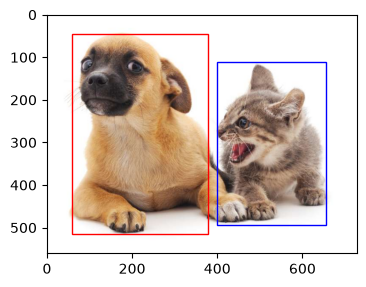

In [53]:
# From Dive into Deep Learning
# (x_corner, y_corner, width, height)
dog_bounding_box = [60.0, 45.0, 378.0, 516.0]
cat_bounding_box = [400.0, 112.0, 655.0, 493.0]

plt.figure(figsize=(4, 6))
cat_dog_image = plt.imread('../img/catdog.jpg')
figure = plt.imshow(cat_dog_image)
figure.axes.add_patch(mylib.bounding_box_center_to_plt(dog_bounding_box, "red"))
figure.axes.add_patch(mylib.bounding_box_center_to_plt(cat_bounding_box, "blue"))
